# Greek-inspired NASA temporal experiment

Actual LSTM/tree/linear training, frozen transfer comparisons and real issued-forecast inputs. The target is next-day satellite-detected vegetation-associated fire occurrence. This is a retrospective research model, not an emergency warning system or a reproduction of the Greek paper's large-fire-danger target. See [the measured report](../docs/greek-experiment-results.md) and [statecharts](../docs/greek-temporal-statecharts.md).

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "forecasting"] if (p / "src/firecast").is_dir())
sys.path.insert(0, str(root / "src"))
from firecast.benchmark_temporal import verify_frozen, evaluate, fit
folder = root / "outputs/greek-temporal-benchmark"
selection, selection_hash = verify_frozen(folder)
manifest = json.loads((root / "outputs/greek-temporal-data/manifest.json").read_text())
display(pd.DataFrame(manifest["parts"]).T[["feature_qualified_windows", "feature_qualified_positive_windows", "excluded_positive_windows"]])
print("Dynamic features:", manifest["dynamic_features"])

,feature_qualified_windows,feature_qualified_positive_windows,excluded_positive_windows
global-train,379751,5605,164
global-calibration,130223,1716,38
global-validation,124883,1862,60
lebanon-train,109567,197,5
lebanon-calibration,35528,98,0
lebanon-validation,35086,32,0
greek-train,118678,67,1
greek-calibration,37199,54,1
greek-validation,37351,20,0


Dynamic features: ['temperature_c', 'T2M_MAX', 'humidity_pct', 'precip_mm', 'wind_u_ms', 'wind_v_ms', 'vpd_kpa', 'GWETROOT', 'GWETTOP']


## Shared training implementation

The real run compared 45 candidates. Fit years are 2018–2020; separate calibration is 2021; selection is 2022 with fourteen-day gaps. Neural adaptations continue actual weights with frozen parent scalers. Trees refit using parent scores. The initial Greek sampled panel had zero training positives, so all Greek dates were collected. Raw NDVI QA, lagged histories and exclusions are implemented in shared modules; excluded positives never become negatives.

In [2]:
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    # This is reproduction on already-viewed data, not new independent confirmation.
    # Use a new output directory; do not overwrite the frozen experiment.
    fit(root / "outputs/greek-temporal-data", root / "outputs/notebook-temporal-reproduction")
else:
    print("Reading completed real-data training artifacts; no retraining or reselection.")
print({k: selection[k] for k in ["candidate_count", "best_global", "best_lebanon", "best_transfer", "fit_seconds"]})
validation = json.loads((folder / "validation-results.json").read_text())
display(pd.DataFrame([{ "model": r["id"], "Lebanese validation AP": r["validation"]["lebanon"]["pr_auc_average_precision"], "global validation AP": r["validation"]["global"]["pr_auc_average_precision"]} for r in validation]).sort_values("Lebanese validation AP", ascending=False).head(10))

Reading completed real-data training artifacts; no retraining or reselection.
{'candidate_count': 45, 'best_global': 'lstm64-global', 'best_lebanon': 'lstm64-lebanon', 'best_transfer': 'logistic-global_greek_lebanon', 'fit_seconds': 415.6511092770015}


,model,Lebanese validation AP,global validation AP
40,lstm64-lebanon,0.003487,0.012558
34,lstm32-lebanon,0.003393,0.012553
20,logistic-global_greek_lebanon,0.003335,0.010557
18,logistic-greek_lebanon,0.003325,0.010667
44,lstm64-global_greek_lebanon,0.003278,0.084843
37,lstm32-global_greek,0.003241,0.119642
16,logistic-lebanon,0.003229,0.010552
43,lstm64-global_greek,0.003131,0.133733
42,lstm64-greek_lebanon,0.003129,0.012461
38,lstm32-global_greek_lebanon,0.003106,0.075973


## Recompute a frozen historical result

This cohort was previously viewed and is not fresh confirmation. The model receives no fire labels; labels are used separately for evaluation. All thresholds remain fixed from validation.

In [3]:
name = "lebanon_known_2023_2025"
with np.load(root / "outputs/greek-known-benchmark-data" / (name + ".npz")) as a:
    data = {k: a[k] for k in a.files}
identifier = selection["best_lebanon"]
artifact = joblib.load(folder / "frozen" / selection["artifacts"][identifier]["file"])
p = artifact["model"].predict({k: v for k, v in data.items() if k != "y"})
recomputed = evaluate(data, p, artifact["thresholds"]["lebanon"])
known = json.loads((folder / "known-results.json").read_text())
assert np.isclose(recomputed["pr_auc_average_precision"], known["results"][identifier][name]["pr_auc_average_precision"])
display({k: recomputed[k] for k in ["observations", "positive_windows", "pr_auc_average_precision", "precision", "recall", "brier", "confusion_matrix_tn_fp_fn_tp"]})

{'observations': 92746,
 'positive_windows': 133,
 'pr_auc_average_precision': 0.007754947137152752,
 'precision': 0.024390243902439025,
 'recall': 0.05263157894736842,
 'brier': 0.0014303054194897413,
 'confusion_matrix_tn_fp_fn_tp': [92333, 280, 126, 7]}

## Registered November confirmation and known-year comparisons

All models and thresholds were frozen before acquiring the new 1/7 November labels. There are zero qualified Lebanese positives, so local AP/recall cannot be estimated. Previously known 2023–2026 scores are separate diagnostics and must not select a replacement winner. A neural chain with better known-year AP did not win validation and is retained only as a comparison.

,feature_qualified_windows,feature_qualified_positive_windows,quarantined_conflict_windows
global_temporal,9946,38,0
global_geographic,3163,53,0
lebanon,172,0,64


,global_known_2023_2025,geographic_known_2023_2025,lebanon_known_2023_2025,lebanon_known_2026_JanOct
lstm64-global,0.173381,0.059386,0.002967,0.002154
lstm64-lebanon,0.010242,0.015072,0.007755,0.004359
logistic-global_greek_lebanon,0.008271,0.018545,0.006116,0.002756
lstm64-global_greek_lebanon,0.058371,0.078291,0.014143,0.005149


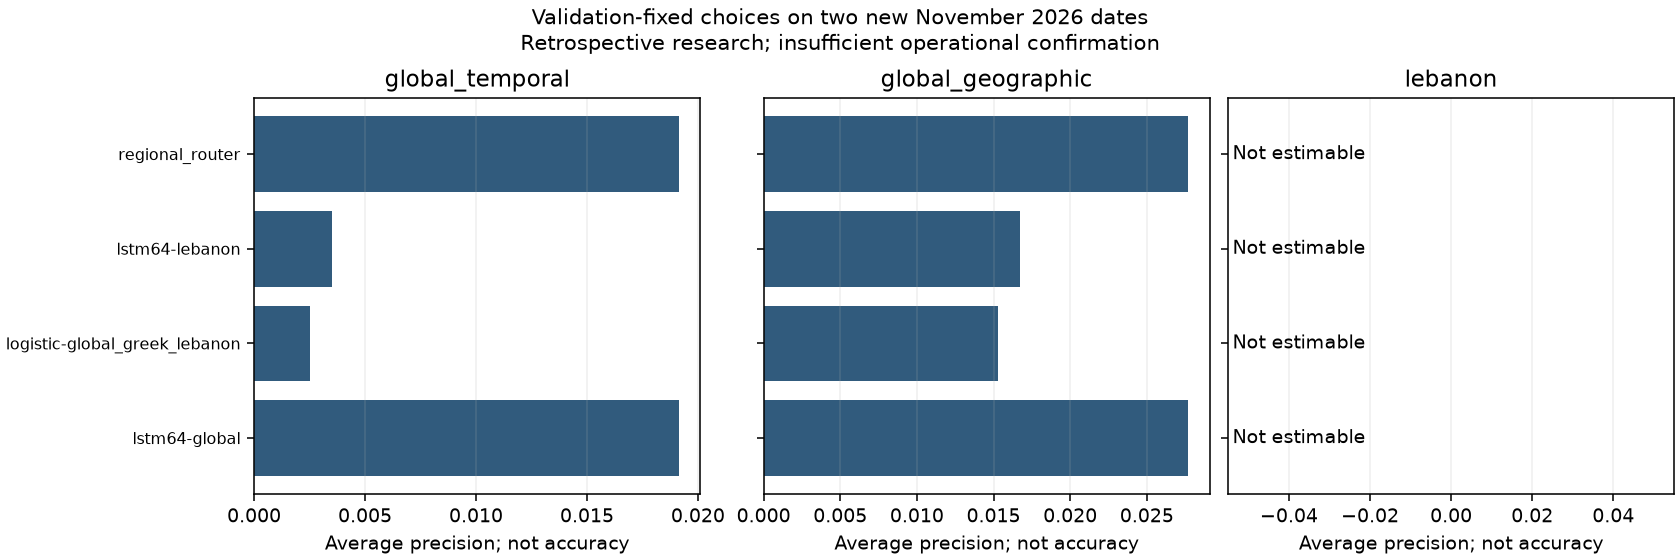

In [4]:
fresh = json.loads((folder / "confirmation-results.json").read_text())
assert fresh["selection_sha256"] == selection_hash
display(pd.DataFrame(fresh["confirmation"]["parts"]).T[["feature_qualified_windows", "feature_qualified_positive_windows", "quarantined_conflict_windows"]])
ids = list(dict.fromkeys([selection["best_global"], selection["best_lebanon"], selection["best_transfer"], "lstm64-global_greek_lebanon"]))
display(pd.DataFrame({i: {d: r["pr_auc_average_precision"] for d, r in known["results"][i].items()} for i in ids}).T)
display(Image(filename=str(root / "docs/figures/greek-temporal-confirmation.png")))

## Actual future NASA inputs and release status

The future-input demonstration preserves actual NASA GEOS issue/valid/retrieval times and actual availability of observed wetness/weather and MODIS vegetation. It contains no future fire labels. Southern scope and missing inputs produce null predictions. This engineering demonstration does not close the historical issued-forecast validation gap.

{'prediction_time': '2026-11-16T00:00:00+00:00',
 'window_end': '2026-11-17T00:00:00+00:00',
 'cells': 124,
 'probabilities_returned': 88,
 'withheld_conflict_scope': 32,
 'model_operationally_validated': False}

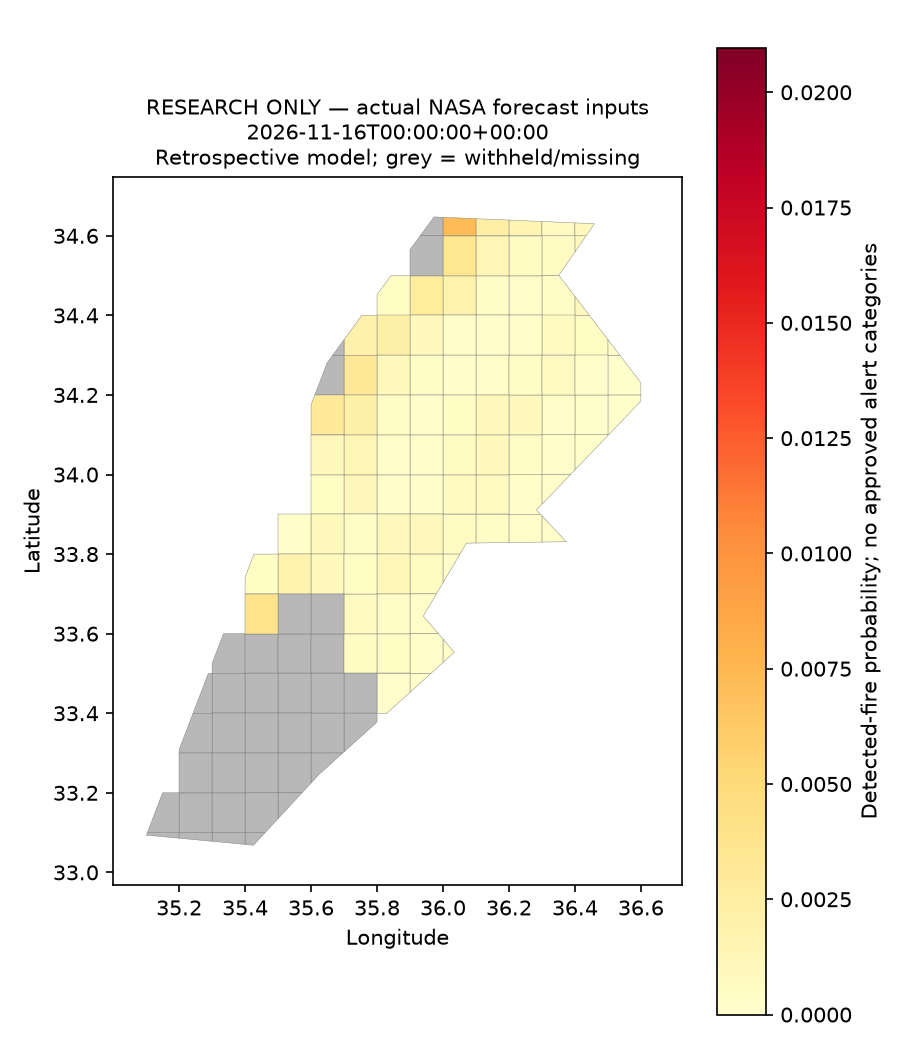

{'approved': False,
 'mode': 'retrospective',
 'failed_requirements': ['issued_forecast_backtest',
  'historical_input_availability',
  'adequate_independent_incident_confirmation',
  'sufficient_test_seasons_and_events',
  'operational_calibration_and_threshold_review'],
 'reason': 'Only two new November dates; historical perfect-weather proxies and reprocessed inputs remain unvalidated for operational forecasting',
 'selected_by_validation': 'lstm64-lebanon',
 'selected_transfer': 'logistic-global_greek_lebanon'}

In [5]:
live = json.loads((root / "outputs/greek-temporal-live/report.json").read_text())
display({k: live[k] for k in ["prediction_time", "window_end", "cells", "probabilities_returned", "withheld_conflict_scope", "model_operationally_validated"]})
display(Image(filename=str(root / "outputs/greek-temporal-live/risk.png")))
release = json.loads((root / "docs/greek-release.json").read_text())
assert release["approved"] is False
assert verify_frozen(folder)[1] == selection_hash
display(release)